# Direct compression examples

In this notebook we will show how to perform full shape fits to data power spectrum, using an emulator to speed up likelihood evaluation.
Look first at notebooks basic_examples.ipynb to get a flavor of *desilike* mechanisms.

## Fake power spectrum data

In [29]:
import numpy as np
from matplotlib import pyplot as plt

from cosmoprimo.fiducial import DESI

cosmo = DESI()
edges = np.linspace(0., 0.3, 31)
edges = np.column_stack([edges[:-1], edges[1:]])
k = np.mean(edges, axis=-1)
nmodes = 4. * np.pi / 3. * (edges[..., 1]**3 - edges[..., 0]**3)
z = 1.
pk = cosmo.get_fourier().pk_interpolator(of='delta_cb')(k, z=z)
b = 2.
f = cosmo.growth_rate(z)
shotnoise = np.ones_like(k) / 5e-4
volume = 1e10

ells = (0, 2, 4)
poles = []
poles.append((b**2 + 2. / 3. * f * b + 1. / 5. * f**2) * pk + shotnoise)
poles.append((4. / 3. * f * b + 4. / 7. * f**2) * pk)
poles.append(8. / 35 * f**2 * pk)
poles = np.array(poles, dtype='f8')

from lsstypes import Mesh2SpectrumPole, Mesh2SpectrumPoles
mean = [Mesh2SpectrumPole(k=k, k_edges=edges, num_raw=value, num_shotnoise=(ell == 0) * shotnoise, ell=ell) for ell, value in zip(ells, poles)]
mean = Mesh2SpectrumPoles(mean)

cov = [2. * (2. * np.pi)**3 / (2 * ell + 1) / (volume * nmodes) * poles[0]**2 for ell in ells]
cov = np.diag(np.concatenate(cov, axis=0))

rng = np.random.RandomState(seed=42)
mocks = []
for i in range(1001):
    tmp = mean.clone(value=rng.multivariate_normal(mean.value().ravel(), cov))
    mocks.append(tmp)
data, mocks = mocks[0], mocks[1:]

## Direct likelihood

In [30]:
from desilike.theories.galaxy_clustering import DirectSpectrum2Template, KaiserTracerSpectrum2Poles
from desilike.observables.galaxy_clustering import Spectrum2PolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike import setup_logging, build, get_params
import lsstypes


template = DirectSpectrum2Template(z=z, fiducial='DESI')
theory = KaiserTracerSpectrum2Poles(template=template)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))  # fit monopole and quadrupole, between 0.02 and 0.2 h/Mpc
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

# NOTE: parameter customization must happen AFTER building the observable above, not before:
# Spectrum2PolesObservable.__init__ calls theory.update(k=..., ells=...) internally to align the
# theory's grid with the data, which (being a full re-__init__) would otherwise silently
# discard any customization made on theory's params beforehand.
params = get_params(observable)
#for name in ['omega_b', 'n_s']: params[name].update(fixed=True)
params['omega_b'].update(fixed=False,
                            prior=dict(dist='norm', loc=DESI()['omega_b'], scale=0.00055),
                            ref=dict(dist='norm', loc=0.02237, scale=0.0003),
                            fd=dict(eps=0.0015), latex=r'\omega_b')
params['n_s'].update(fixed = False,
                        value=DESI()['n_s'],
                        prior=dict(dist='norm', loc=0.9649, scale=0.042 / 10 * 2),
                        ref=dict(dist='norm', loc=DESI()['n_s'], scale=0.1),
                        fd=dict(eps=0.005), latex='n_s')
params['b1'].update(value=2.)  # start from the truth

likelihood = ObservablesGaussianLikelihood(observables=[observable])

# NOTE: if we wanted to fit xi instead:
# theory = KaiserTracerCorrelation2Poles(template=template)
# observable = Correlation2PolesObservable(data=data_sel, covariance=covariance,
#                                          theory=theory)  # with data_sel = data.get(ells=[0, 2]).select(s=(40., 160.))
# The rest would be the same

setup_logging()
pipe = build(likelihood)
print('logL at default parameters =', pipe())

logL at default parameters = -17.968458230564504


In [31]:
from desilike.emulators import Emulator, Space

# Emulate the theory as set up by the observable (k and ells aligned with the data).
# A `Space` is where the emulator must be accurate: the region the chain will explore, not the
# whole prior -- over-covering is the most expensive mistake available here. `Space(theory)`
# would read the box off each parameter's `ref`, but desilike's default refs are normal
# distributions with no finite limits, so state it explicitly: 5 sigma of those ref scales.
#space = Space(bounds={'h': (0.65, 0.70), 'omega_cdm': (0.114, 0.126), 'logA': (2.97, 3.11),
#                      'b1': (1.6, 2.4), 'sn0': (-0.5, 0.5)},
space = Space(bounds={'h': (0.65, 0.70),
                                                         'omega_cdm': (0.116, 0.128),
                                                         'logA': (2.97, 3.11),
                                                         'omega_b': (0.020005, 0.024995),
                                                         'n_s': (0.8, 1.1),
                      'b1': (1.6, 2.4), 'sn0': (-0.5, 0.5)
                                                        }, 
              # per-axis resolution, a different knob from `budget` (the total degree of the
              # interpolant, which buys the interaction terms): the theory is linear in sn0,
              # so a single level is exact along that axis
              levels={'sn0': 1})
emulator = Emulator(theory, space, budget=2)
print(len(emulator.nodes()), 'nodes')  # size the training before paying for it
emulator.train()

# `to_calculator()` returns an instance of the theory's own class whose state is predicted
# rather than computed -- a drop-in wherever the original went. It deploys onto a copy of the
# calculator it was built from, so the pipeline this emulator came from stays usable: both
# graphs live, and they share their Parameters by name.
emulated = emulator.to_calculator()

# An emulated calculator returns `self` (it is built to be a dependency, read through its
# attributes), so evaluate it and read `.poles`.
point = dict(h=0.68, omega_cdm=0.122, logA=3.05, b1=2.1, sn0=0.1)
poles_true = np.asarray(build(theory)(**point))
build(emulated)(**point)
print('Max relative emulation error:', np.max(np.abs(np.asarray(emulated.poles) / poles_true - 1.)))

import os
base_dir = '_tests'
os.makedirs(base_dir, exist_ok=True)
kaiser_emulator_fn = os.path.join(base_dir, 'kaiser_emulator.h5')
emulator.write(kaiser_emulator_fn)

111 nodes
[000009.73]  10-14 05:26  Emulator                     INFO     training on 111 nodes over 7 parameters; 0 handled exactly
[000009.74]  10-14 05:26  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.116, 0.128], logA [2.97, 3.11], omega_b [0.020005, 0.024995], n_s [0.8, 1.1], b1 [1.6, 2.4], sn0 [-0.5, 0.5]
[000009.74]  10-14 05:26  TrainingSet                  INFO     111/111 nodes to evaluate; no checkpoint (nothing is resumable)
[000049.81]  10-14 05:26  TrainingSet                  INFO     50/111 nodes
[000108.86]  10-14 05:27  TrainingSet                  INFO     100/111 nodes
[000124.21]  10-14 05:28  TrainingSet                  INFO     training complete (111/111 nodes)
Max relative emulation error: 4.997633151804237e-05


'_tests/kaiser_emulator.h5'

## Sampling
Let us draw MC samples of the likelihood (actually posterior, including parameter priors).

In [32]:
from desilike import Sampler, Posterior
from desilike.samplers import Zeus

# Swap the theory for its emulator: update() re-runs the observable's __init__ in-place with
# the new theory (the likelihood holds the same observable instance, so it picks up the swap
# when we rebuild below). The emulator read back from file has no Calculator of its own,
# so it is handed the constructor arguments it needs.
emulated = Emulator.read(kaiser_emulator_fn).to_calculator()
observable.update(theory=emulated)
# The emulated theory exposes exactly the parameters it was trained over -- h, omega_cdm, logA,
# b1, sn0. `omega_b` and `n_s` are not among them: they were held fixed during training, so the
# emulator has them baked in and they are no longer pipeline parameters at all. (Deploying used
# to reconstruct a default template that re-declared them, which was worse than useless -- the
# default template is not the one the emulator was trained with.)
params = get_params(observable)
params['b1'].update(value=2.)

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior.
# (Outside its trained box the emulator predicts NaN, i.e. -inf posterior, so the sampler
# rejects those points instead of extrapolating -- one more reason for the box to cover the
# posterior amply.)
pipe = build(Posterior(likelihood))
! rm -rf _tests/chain_fs_direct
sampler = Sampler(pipe, kernel=Zeus(), rng=42, output_dir='_tests/chain_fs_direct')
# We run samples until convergence, considered reached when Gelman-Rubin stabilizes below 1.05
samples = sampler.run(min_steps=1000, gelman_rubin=1.02)

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
[000130.06]  10-14 05:28  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s', 'b1', 'sn0']
[000130.06]  10-14 05:28  EnsembleSampler              INFO     Samples will be written to: _tests/chain_fs_direct


/global/homes/d/dforero/codes/desilike/desilike/samplers/zeus.py:67: UserWarning: Zeus does not support random seeds. Results are not deterministic.
  warnings.warn('Zeus does not support random seeds. Results are not deterministic.')


[000130.45]  10-14 05:28  root                         INFO     Initialising ensemble of 28 walkers...
[000142.67]  10-14 05:28  EnsembleSampler              INFO     Diagnostics:
[000142.71]  10-14 05:28  EnsembleSampler              INFO     Gelman-Rubin: 1.02
[000142.71]  10-14 05:28  EnsembleSampler              INFO     1.02 < 1.02 (passed)
[000142.71]  10-14 05:28  EnsembleSampler              INFO     Geweke: 0.152
[000142.71]  10-14 05:28  EnsembleSampler              INFO     Effective Sample Size: 448
[000142.72]  10-14 05:28  root                         INFO     Initialising ensemble of 28 walkers...
[000145.71]  10-14 05:28  EnsembleSampler              INFO     Diagnostics:
[000145.75]  10-14 05:28  EnsembleSampler              INFO     Gelman-Rubin: 1.03
[000145.75]  10-14 05:28  EnsembleSampler              INFO     1.03 >= 1.02 (not passed)
[000145.75]  10-14 05:28  EnsembleSampler              INFO     Geweke: 0.18
[000145.75]  10-14 05:28  EnsembleSampler            

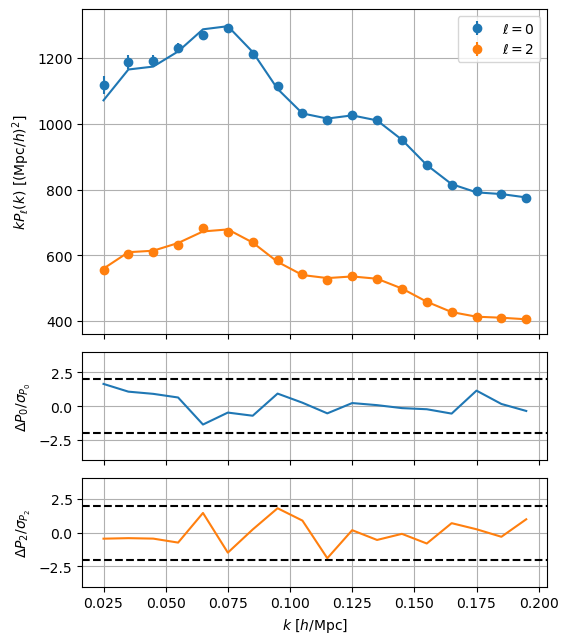

In [33]:
# Evaluate the likelihood at the maximum-posterior sample and plot the fit
names = get_params(likelihood).select(varied=True, derived=False).names()
idx = np.unravel_index(np.argmax(samples.logposterior), samples.logposterior.shape)
best = {name: np.asarray(samples[name].value)[idx] for name in names}
pipe(**best)
observable.plot()
plt.show()

In [34]:
chain = samples.remove_burnin(0.5)[::10]
print(chain.to_stats(tablefmt='pretty'))

+-----------+---------+---------+---------+--------+-----------------+-----------------+
|           | argmax  |  mean   | median  |  std   | quantile:1sigma | interval:1sigma |
+-----------+---------+---------+---------+--------+-----------------+-----------------+
|     h     | 0.6807  | 0.6776  | 0.6776  | 0.0065 | +0.0066/-0.0064 | +0.0062/-0.0067 |
| omega_cdm | 0.1192  | 0.1191  | 0.1189  | 0.0017 | +0.0018/-0.0017 | +0.0015/-0.0019 |
|   logA    |  3.040  |  3.042  |  3.043  | 0.015  |  +0.016/-0.015  |  +0.016/-0.015  |
|  omega_b  | 0.02244 | 0.02240 | 0.02239 | 4.9e-4 | +4.9e-4/-4.7e-4 | +4.8e-4/-4.8e-4 |
|    n_s    | 0.9697  | 0.9698  | 0.9699  | 0.0054 | +0.0054/-0.0056 | +0.0053/-0.0056 |
|    b1     |  1.990  |  1.992  |  1.992  | 0.012  |  +0.013/-0.013  | +0.0152/-0.0091 |
|    sn0    | 0.0026  | 0.0015  | 0.0015  | 0.0029 | +0.0030/-0.0028 | +0.0025/-0.0033 |
+-----------+---------+---------+---------+--------+-----------------+-----------------+


Removed no burn in


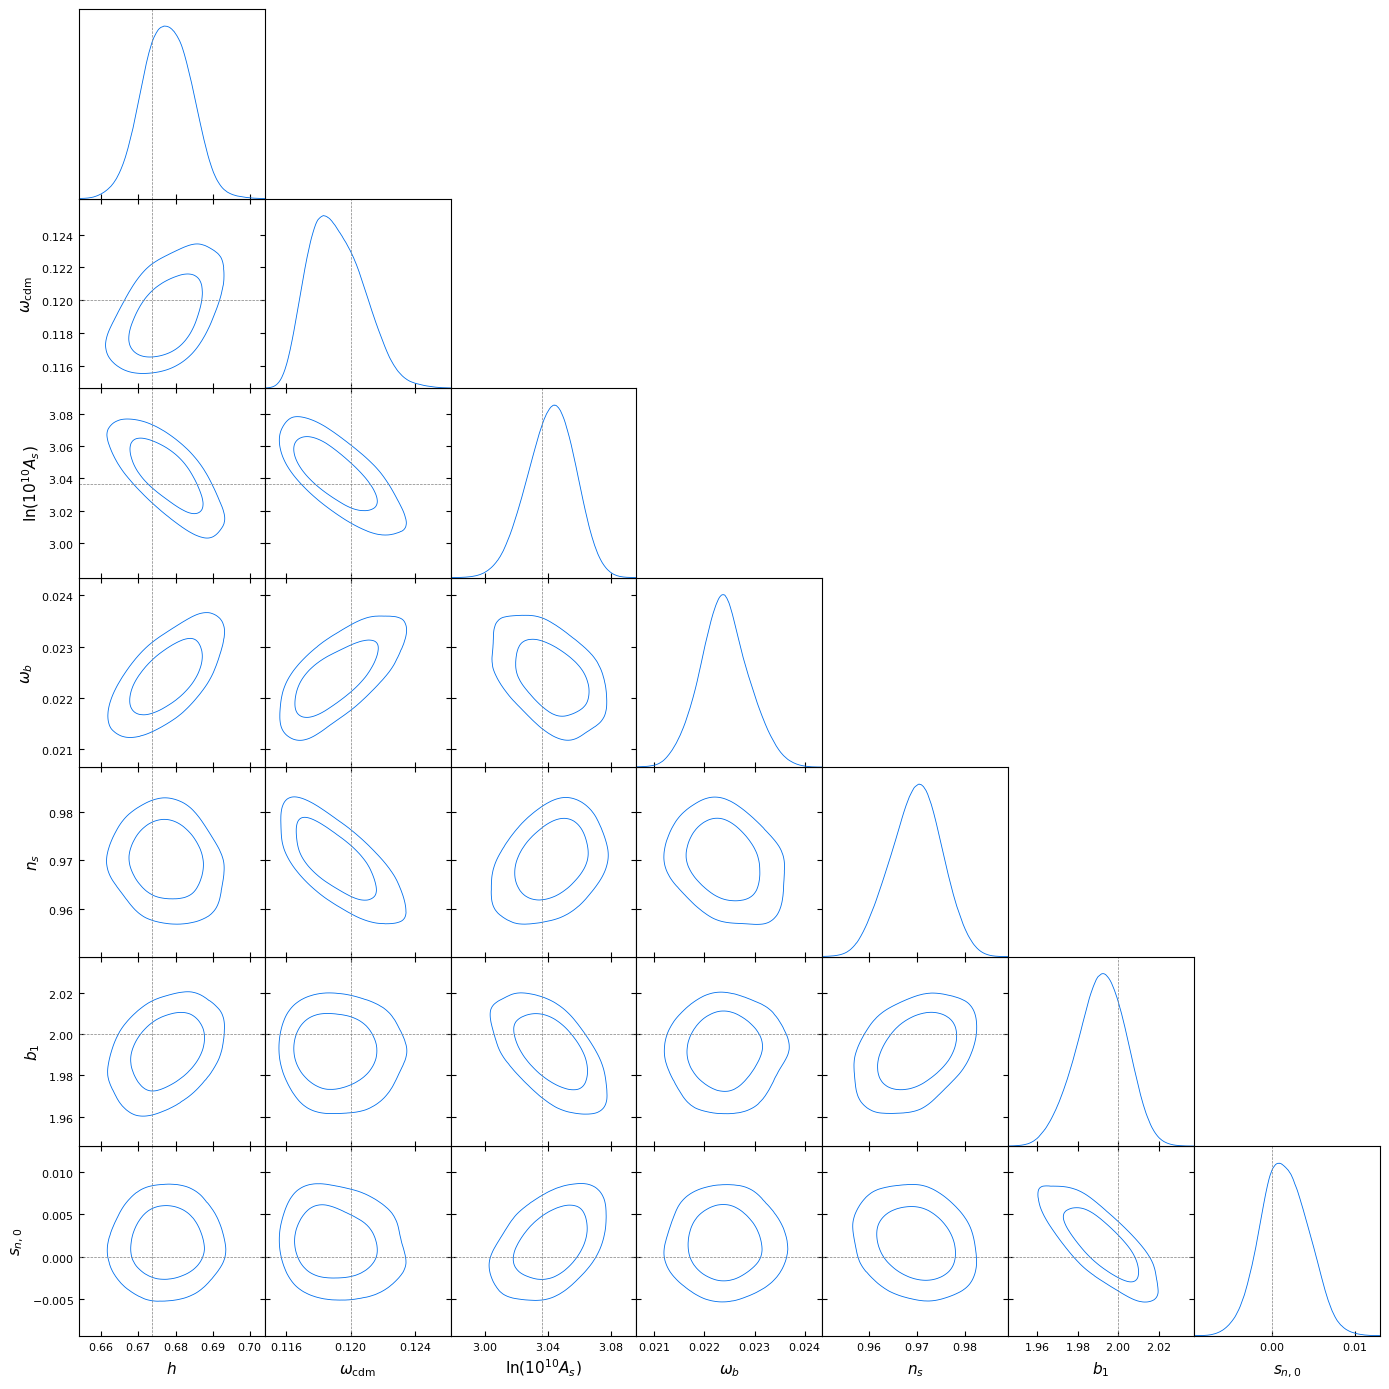

In [35]:
from desilike.samples import plotting
# NOTE: no derived Omega_m parameter on this branch's DirectSpectrum2Template; the chain
# contains the sampled base parameters directly
plotting.plot_triangle(chain, markers={'h': cosmo.h, 'omega_cdm': cosmo.Omega0_cdm * cosmo.h**2,
                                       'logA': np.log(10**10 * cosmo.A_s), 'b1': b, 'sn0': 0.})

# Do FM on the bispectrum too

## Generate fake bispectra

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/code/cosmoprimo/main/lib/python3.12/site-packages/cosmoprimo/eisenstein_hu.py:25: UserWarning: EisensteinHuNoWiggleEngine cannot cope with massive neutrinos
  warnings.warn(


⚠️ JAX is using CPU. Devices: [CpuDevice(id=0)]
Calculating matrices (no save path specified)


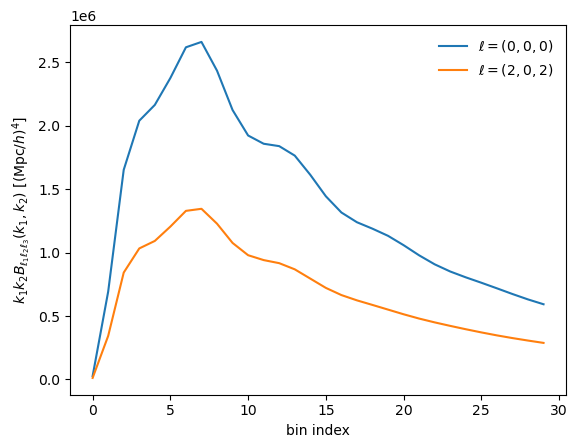

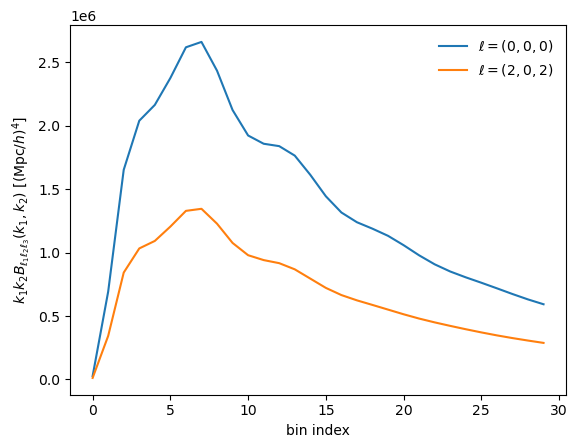

In [36]:
from desilike.theories.galaxy_clustering import FOLPSTracerSpectrum3Poles
from desilike.theories.galaxy_clustering.template import DirectSpectrum2Template
from lsstypes import Mesh3SpectrumPole, Mesh3SpectrumPoles

edges = np.linspace(0., 0.3, 31)
edges = np.column_stack([edges[:-1], edges[1:]])
k = np.mean(edges, axis=-1)     
theory_b = FOLPSTracerSpectrum3Poles(template=DirectSpectrum2Template(z = z, fiducial = 'DESI'),
                                            k = np.c_[k, k])

b1, b2, bs = b, 0.5, -0.2
theory_graph = build(theory_b)
theory_values = theory_graph(b1 = b1, b2 = b2, bs = bs, c1 = 0, c2 = 0, X_FoG = 0)
poles = []
for ill, ell in enumerate(theory_b.ells):
    
    pole = Mesh3SpectrumPole(
                k=np.c_[k, k],                # shape (n_k, 2)
                k_edges=np.c_[edges, edges].reshape(-1, 2, 2),  # (n_k, 2, 2)
                num_raw=theory_values[ill],
                ell=theory_b.ells[ill],
                basis='sugiyama'
            )
    poles.append(pole)
mean_bispec = Mesh3SpectrumPoles(poles)
mean_bispec.plot()


In [37]:

k1 = k
k2 = k
dk = np.diff(edges)
dk1_2d, dk2_2d = np.meshgrid(dk, dk, indexing='ij')
k1_2d, k2_2d = np.meshgrid(k1, k2, indexing='ij')
volume = 1e10
# Phase-space volume factor for triangles
nmodes_k = 8 * np.pi**2 * k1_2d**2 * k2_2d**2 * dk1_2d * dk2_2d
N_tri = nmodes_k * volume / (2 * np.pi)**6
N_tri = np.maximum(N_tri, 1).astype('i8')

def safe_pk(k, b1, z):
    pk = cosmo.get_fourier().pk_interpolator(of='delta_cb')(k.ravel(), z=z)
    return b1**2 * pk.reshape(k.shape)
p1_2d = safe_pk(k1_2d, b1, z)
p2_2d = safe_pk(k2_2d, b1, z)
k3_mean = np.sqrt(k1_2d**2 + k2_2d**2) # representative k3 for disconnected covariance
p3_2d = safe_pk(k3_mean, b1, z)

var = []
for ell in mean_bispec.ells:
    ell_factor = 1
    for ll in ell:
        ell_factor *= 2 * (ll + 1)
    # Disconnected bispectrum covariance scales roughly as P1 * P2 * P3 / N_tri
    v = ell_factor * p1_2d * p2_2d * p3_2d / N_tri
    v = v + np.max(v) * 1e-4 # Add a numerical floor to avoid exactly zero variance
    var.append(np.diag(v))

cov_b = np.diag(np.concatenate(var))



In [38]:
rng = np.random.RandomState(seed=42)
mocks_bispec = []
for i in range(1001):
    tmp = mean_bispec.clone(value=rng.multivariate_normal(mean_bispec.value().ravel(), cov_b))
    mocks_bispec.append(tmp)

data_bispec, mocks_bispec = mocks_bispec[0], mocks_bispec[1:]
print(f"Successfully generated data and {len(mocks)} mocks for bispectrum.")



Successfully generated data and 1000 mocks for bispectrum.


In [39]:

from desilike.theories.galaxy_clustering import FOLPSTracerSpectrum3Poles
from desilike.observables.galaxy_clustering import Spectrum3PolesObservable
template_b = DirectSpectrum2Template(z=z, fiducial='DESI')
theory_b = FOLPSTracerSpectrum3Poles(template=template_b)

data_sel = data.get(ells=[0, 2]).select(k=(0.02, 0.2))  # fit monopole and quadrupole, between 0.02 and 0.2 h/Mpc
covariance = lsstypes.cov(mocks).at.observable.match(data_sel)
observable = Spectrum2PolesObservable(data=data_sel, covariance=covariance, theory=theory)

covariance_b = lsstypes.cov(mocks_bispec).at.observable.match(data_bispec)
observable_b = Spectrum3PolesObservable(data=data_bispec, covariance=covariance_b, theory=theory_b)


In [40]:

from lsstypes import ObservableTree

# For each mock realisation
combined_mocks = []
for imock in range(1000):
    p_poles = mocks[imock]                 # Mesh2SpectrumPoles
    b_poles = mocks_bispec[imock]          # Mesh3SpectrumPoles (raveled)

    # Pack them into a single tree with labels
    combined = ObservableTree(
        branches=[p_poles, b_poles],
        observables=['spectrum2poles', 'spectrum3poles'],
        tracers=[('LRG', 'LRG'), ('LRG', 'LRG', 'LRG')]   # adjust to your tracers
    )
    combined_mocks.append(combined)

# Compute covariance over the list of combined mocks
joint_cov = lsstypes.cov(combined_mocks)



combined_observable = ObservableTree(
        branches=[data_sel, data_bispec],
        observables=['spectrum2poles', 'spectrum3poles'],
        tracers=[('LRG', 'LRG'), ('LRG', 'LRG', 'LRG')]   # adjust to your tracers
    )

In [41]:

# NOTE: parameter customization must happen AFTER building the observable above, not before:
# Spectrum2PolesObservable.__init__ calls theory.update(k=..., ells=...) internally to align the
# theory's grid with the data, which (being a full re-__init__) would otherwise silently
# discard any customization made on theory's params beforehand.
# The two theories each declare their own b1 and sn0, and this is one tracer: a joint P+B fit
# must vary a single copy of each. `share_params` makes that explicit -- same-named Parameters
# that are distinct objects are unified only when they agree, and these do not (the two theories
# propose different defaults), so the build refuses the tree rather than silently keeping one
# side's prior. Done here, after the observables above re-ran the theories' __init__.
from desilike.base import share_params

share_params([theory, theory_b])

params = get_params(observable)
params['b1'].update(value=b1)  # start from the truth
for name in ['omega_b', 'n_s']: params[name].update(fixed=True)
# Narrow reference distributions (used to draw starting points for profilers / samplers)


params = get_params(observable_b)
params['b1'].update(value=b1)  # start from the truth
params['b2'].update(value=b2)  # start from the truth
params['bs'].update(value=bs)  # start from the truth
# Narrow reference distributions (used to draw starting points for profilers / samplers)
params['c1'].update(fixed = True, value = 0.)
params['c2'].update(fixed = True, value = 0.)
params['X_FoG'].update(fixed = True, value = 0.)
for name in ['omega_b', 'n_s']: params[name].update(fixed=True)


likelihood = ObservablesGaussianLikelihood(observables=[observable, observable_b], covariance = joint_cov)

# NOTE: if we wanted to fit xi instead:
# theory = KaiserTracerCorrelation2Poles(template=template)
# observable = Correlation2PolesObservable(data=data_sel, covariance=covariance,
#                                          theory=theory)  # with data_sel = data.get(ells=[0, 2]).select(s=(40., 160.))
# The rest would be the same

setup_logging()
pipe = build(likelihood)
print('logL at default parameters =', pipe())


Calculating matrices (no save path specified)
logL at default parameters = -48.04354515748223


In [42]:
from desilike.emulators import Emulator, Space

# Same for the bispectrum theory. b2, bs, sn0 and snb0 enter the tree-level bispectrum
# linearly, so a single level is exact along those axes; `budget` then buys the interaction
# terms between the remaining ones.
space = Space(bounds={'h': (0.65, 0.70), 'omega_cdm': (0.114, 0.126), 'logA': (2.97, 3.11),
                      'b1': (1.6, 2.4), 'b2': (-3., 4.), 'bs': (-3.5, 3.),
                      'sn0': (-0.5, 0.5), 'snb0': (-1.5, 1.5)},
              levels={'b2': 1, 'bs': 1, 'sn0': 1, 'snb0': 1})
emulator_b = Emulator(theory_b, space, budget=2)
print(len(emulator_b.nodes()), 'nodes')
emulator_b.train()

emulated_b = emulator_b.to_calculator()
point = dict(h=0.68, omega_cdm=0.122, logA=3.05, b1=2.1, b2=0.6, bs=-0.3, sn0=0.1, snb0=0.1)
poles_true = np.asarray(build(theory_b)(**point))
build(emulated_b)(**point)
print('Max relative emulation error:', np.max(np.abs(np.asarray(emulated_b.poles) / poles_true - 1.)))

import os
base_dir = '_tests'
os.makedirs(base_dir, exist_ok=True)
bispec_emulator_fn = os.path.join(base_dir, 'bispec_FM_emulator.h5')
emulator_b.write(bispec_emulator_fn)

Calculating matrices (no save path specified)
137 nodes
[000018.89]  10-14 05:29  Emulator                     INFO     training on 137 nodes over 8 parameters; 0 handled exactly
[000018.89]  10-14 05:29  Emulator                     INFO     node box: h [0.65, 0.7], omega_cdm [0.114, 0.126], logA [2.97, 3.11], b1 [1.6, 2.4], b2 [-3, 4], bs [-3.5, 3], sn0 [-0.5, 0.5], snb0 [-1.5, 1.5]
[000018.89]  10-14 05:29  TrainingSet                  INFO     137/137 nodes to evaluate; no checkpoint (nothing is resumable)
[000021.28]  10-14 05:29  TrainingSet                  INFO     50/137 nodes
[000059.21]  10-14 05:29  TrainingSet                  INFO     100/137 nodes
[000097.61]  10-14 05:30  TrainingSet                  INFO     training complete (137/137 nodes)
Calculating matrices (no save path specified)
Max relative emulation error: 0.00044101426346088157


'_tests/bispec_FM_emulator.h5'

In [43]:
from desilike import Sampler, Posterior
from desilike.samplers import Zeus, PocoMC, Nautilus, Emcee, Dynesty


# Swap both theories for their emulators: update() re-runs each observable's __init__ in-place
# with the new theory (the likelihood holds the same observable instances, so it picks up the
# swaps when we rebuild below).
emulated_b = Emulator.read(bispec_emulator_fn).to_calculator()
observable_b.update(theory=emulated_b)

emulated = Emulator.read(kaiser_emulator_fn).to_calculator()
observable.update(theory=emulated)

# An emulated theory exposes exactly the parameters it was trained over, so only those can be
# customized here. `c1`, `c2`, `X_FoG`, `omega_b` and `n_s` were held fixed during training: the
# emulators carry them at those values and they are no longer pipeline parameters at all.
# (Deploying used to re-run the theory's __init__, which re-declared them -- and, worse, built a
# default template that was not the one the emulator was trained with.)
params = get_params(observable)
params['b1'].update(value=b1)

params = get_params(observable_b)
params['b1'].update(value=b1)
params['b2'].update(value=b2)
params['bs'].update(value=bs)

# Sample the posterior = likelihood + priors: wrap the likelihood in Posterior.
# (Outside its trained box the emulator predicts NaN, i.e. -inf posterior, so the sampler
# rejects those points instead of extrapolating.)
pipe = build(Posterior(likelihood))
! rm -rfv _tests/chain_fs_FM_bispec/
sampler = Sampler(pipe, kernel=Emcee(), rng=42, output_dir='_tests/chain_fs_FM_bispec')
# We run samples until convergence, considered reached when Gelman-Rubin stabilizes below 1.05
samples = sampler.run(min_steps=10000, gelman_rubin=1.01)
#samples = sampler.run()

/global/common/software/desi/users/adematti/perlmutter/cosmodesiconda/20260321-1.0.0/conda/lib/python3.12/pty.py:95: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
removed '_tests/chain_fs_FM_bispec/samples_1.h5'
removed '_tests/chain_fs_FM_bispec/checks.json'
removed '_tests/chain_fs_FM_bispec/rng_1.json'
removed directory '_tests/chain_fs_FM_bispec/'
[000112.27]  10-14 05:30  EnsembleSampler              INFO     Varied parameters: ['h', 'omega_cdm', 'logA', 'omega_b', 'n_s', 'b1', 'sn0', 'b2', 'bs', 'snb0']
[000112.27]  10-14 05:30  EnsembleSampler              INFO     Samples will be written to: _tests/chain_fs_FM_bispec
[000114.11]  10-14 05:30  Emcee                        INFO     total likelihood evaluations: 11960
[000114.21]  10-14 05:30  EnsembleSampler              INFO     Diagnostics:
[000114.26]  10-14 05:30  EnsembleSampler              INFO     Gelman-Rubin: 2.12
[000114.26]  10-14 05:30  Ense

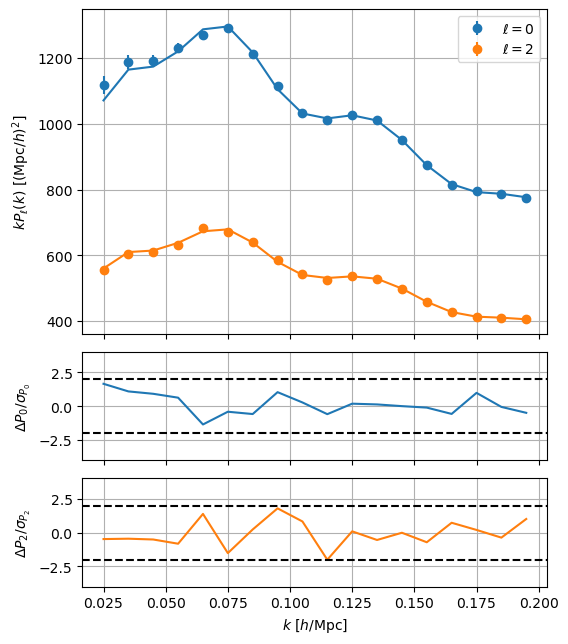

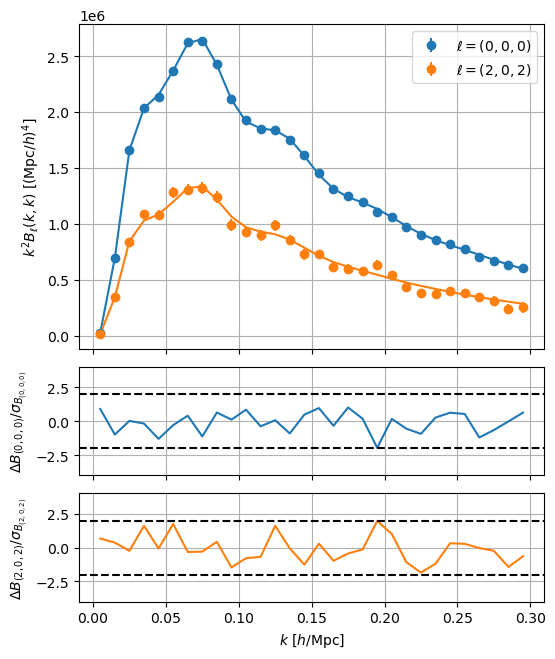

In [44]:
# Evaluate the likelihood at the maximum-posterior sample and plot the fit
names = get_params(likelihood).select(varied=True, derived=False).names()
idx = np.unravel_index(np.argmax(samples.logposterior), samples.logposterior.shape)
best = {name: np.asarray(samples[name].value)[idx] for name in names}
pipe(**best)
observable.plot()
observable_b.plot()
plt.show()

In [45]:
chain = samples.remove_burnin(0.2)[::2]
print(chain.to_stats(tablefmt='pretty'))

+-----------+---------+---------+---------+---------+-----------------+-----------------+
|           | argmax  |  mean   | median  |   std   | quantile:1sigma | interval:1sigma |
+-----------+---------+---------+---------+---------+-----------------+-----------------+
|     h     | 0.6768  | 0.6766  | 0.6766  | 0.0039  | +0.0039/-0.0040 | +0.0040/-0.0039 |
| omega_cdm | 0.11880 | 0.11882 | 0.11882 | 0.00070 | +7.0e-4/-7.1e-4 | +7.0e-4/-7.0e-4 |
|   logA    |  3.045  |  3.044  |  3.044  |  0.011  |  +0.011/-0.011  |  +0.011/-0.011  |
|  omega_b  | 0.02222 | 0.02229 | 0.02230 | 3.2e-4  | +3.2e-4/-3.2e-4 | +3.4e-4/-3.1e-4 |
|    n_s    | 0.9696  | 0.9706  | 0.9706  | 0.0038  | +0.0038/-0.0038 | +0.0038/-0.0038 |
|    b1     |  1.987  |  1.990  |  1.990  |  0.012  |  +0.012/-0.012  |  +0.012/-0.011  |
|    sn0    | 0.0026  | 0.0019  | 0.0019  | 0.0029  | +0.0028/-0.0028 | +0.0029/-0.0028 |
|    b2     |  0.487  |  0.477  |  0.477  |  0.045  |  +0.045/-0.045  |  +0.044/-0.046  |
|    bs   

Removed no burn in
[000136.22]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, omega_cdm
[000136.29]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, logA
[000136.38]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, omega_b
[000136.45]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, n_s
[000136.51]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, b1
[000136.57]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, sn0
[000136.64]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, b2
[000136.71]  10-14 05:31  root                         WARNING  fine_bins_2D not large enough for optimal density: h, 

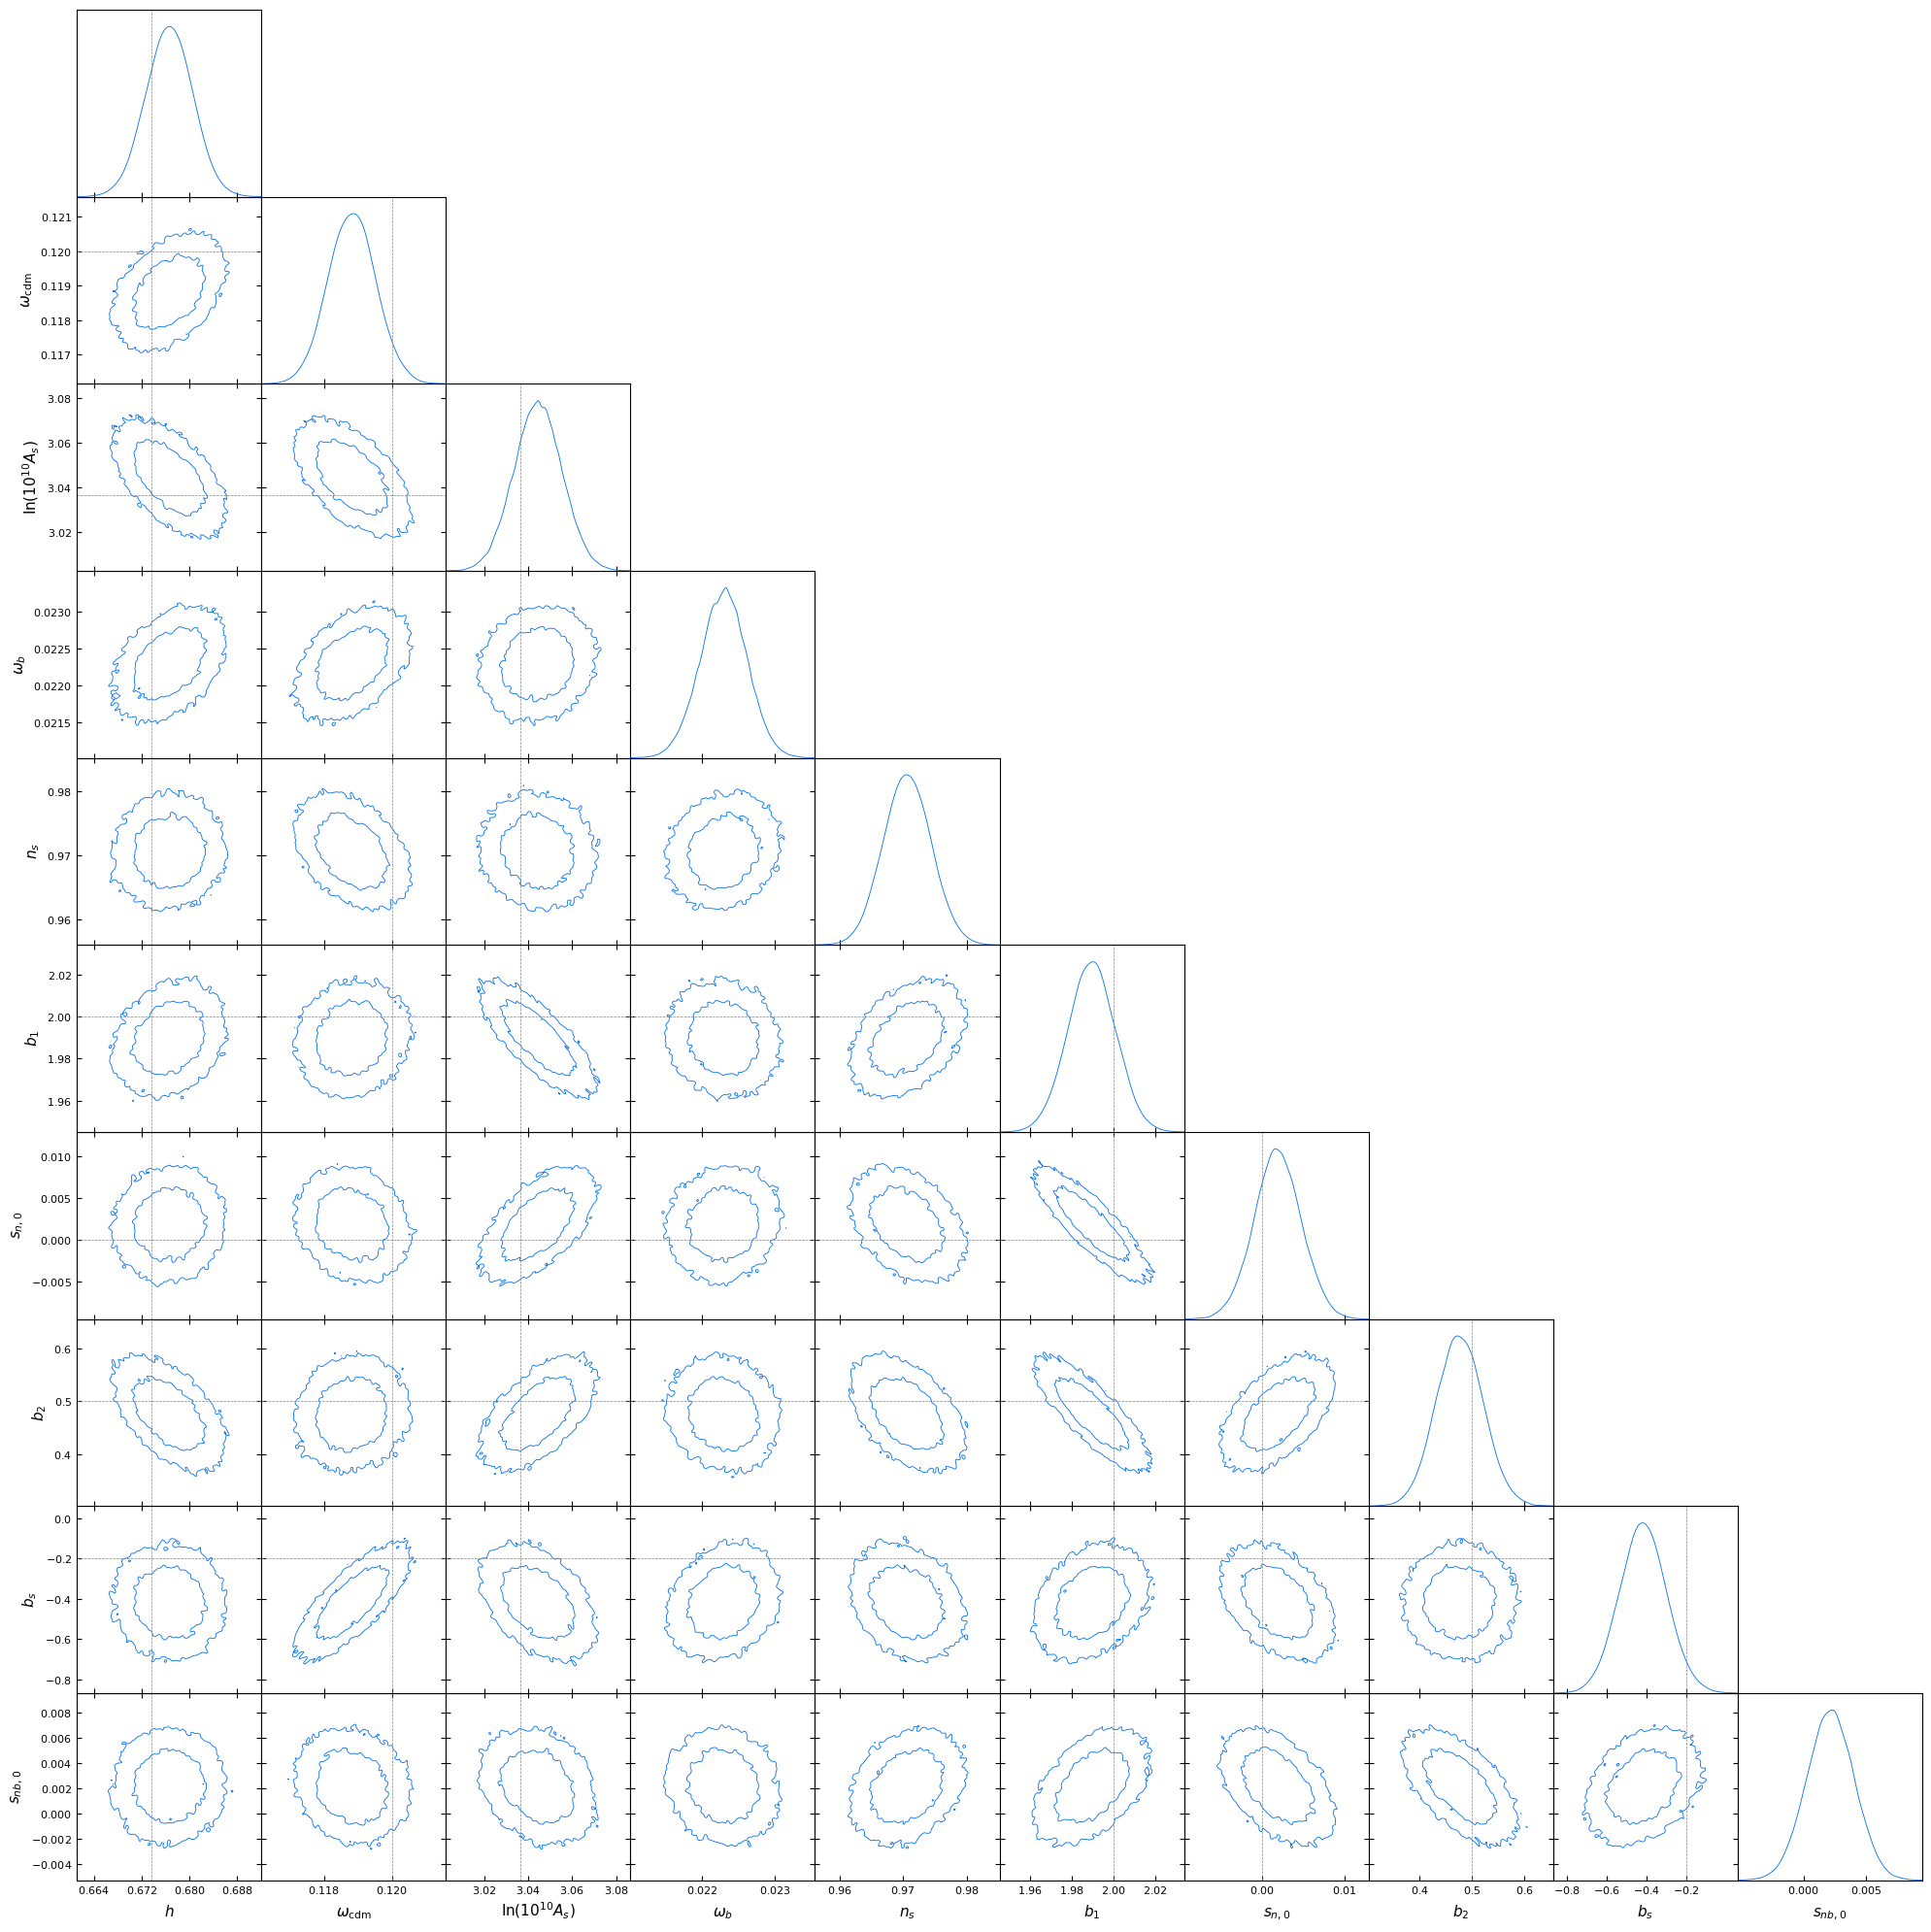

In [46]:
from desilike.samples import plotting
# NOTE: no derived Omega_m parameter on this branch's DirectSpectrum2Template; the chain
# contains the sampled base parameters directly
plotting.plot_triangle(chain, markers={'h': cosmo.h, 'omega_cdm': cosmo.Omega0_cdm * cosmo.h**2,
                                       'logA': np.log(10**10 * cosmo.A_s), 'b1': b, 'sn0': 0., 'b2':b2, 'bs':bs, 'sn0b':0})